# Spatial CNV inference on Xenium

Imaging-based spatial transcriptomics (Xenium, CosMx, MERSCOPE) measures a few thousand genes in hundreds of
thousands of cells, with a few hundred counts per cell. inferCNV-style profiles of single cells are noisy at that
depth, but the tissue coordinates add information: neighbouring tumour cells usually share their copy number state.
This tutorial shows the spatial layer of infercnvpy:

- {func}`infercnvpy.tl.smooth_cnv` averages each cell's CNV profile with its spatial neighbours,
- {func}`infercnvpy.tl.spatial_regions` makes per-cell labels (here tumour/normal calls) spatially coherent: a cell
  takes the label of its neighbourhood when most of its neighbours disagree with it (more than 75% at the default
  `beta`),
- {func}`infercnvpy.pl.spatial_cnv` plots the mean CNV of a chromosome or arm on the tissue.

All three read a spatial neighbour graph from `adata.obsp`, here from {func}`squidpy.gr.spatial_neighbors_knn`; any
cells x cells graph works. To run this tutorial, install squidpy, gtfparse and the lazy readers of anndata with the optional extras, and s3fs to
read the data from S3: `pip install "infercnvpy[spatial,gtf,dask]" s3fs`.

The ideas are not new. InSituCNV {cite}`Jensen2025` smooths infercnvpy profiles over kNN neighbours on Xenium and CosMx,
SlideCNA {cite}`Zhang2025` pools spatial neighbours on Slide-seq, and STARCH {cite}`Elyanow2021` and CalicoST
{cite}`Ma2024` make neighbouring cells prefer the same clone label. In a benchmark of CNV inference on spatial data,
{cite:t}`Han2026` found that aggregating cells on imaging platforms improved CNV recovery compared to native
single-cell resolution.

We use a Xenium Prime 5K section of a squamous cell lung carcinoma from {cite:t}`Bilous2026`, distributed under GEO
terms through the scverse spatial data catalogue. Squamous lung cancers typically lose 3p and gain 3q.

In [1]:
import anndata as ad
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
import squidpy as sq
import zarr

import infercnvpy as cnv

sc.set_figure_params(dpi=50, frameon=False, figsize=(4.5, 4.5))

## Load the data

The dataset is a SpatialData object on S3. We only need its table, which we open lazily with
{func}`anndata.experimental.read_lazy` and then load the counts, the cell metadata and the cell centroids into memory.
Images, transcripts and segmentation shapes are never downloaded.

In [2]:
group = zarr.open_group(
    "s3://scverse-spatial-eu-central-1/.lamindb/cOjo8Fe6mVpB4Mu0.zarr/tables/table",
    mode="r",
    storage_options={"anon": True},
)
lazy = ad.experimental.read_lazy(group)
obs = lazy.obs.to_memory()[["cell_id", "total_counts", "cell_area"]]
obs.index = obs.pop("cell_id").astype(str).to_numpy()
adata = ad.AnnData(
    X=lazy.X.compute(),
    obs=obs,
    var=lazy.var.to_memory()[["gene_ids"]],
    obsm={"spatial": lazy.obsm["spatial"].compute()},
)
adata

AnnData object with n_obs × n_vars = 64872 × 5001
    obs: 'total_counts', 'cell_area'
    var: 'gene_ids'
    obsm: 'spatial'
    layers: None (.X)

We drop cells with fewer than 50 counts and log-normalise to 10,000 counts per cell. The CNV values are log fold
changes, so the normalisation target sets their scale: with the default target (the median of the remaining cells),
most values are `log1p` of 0 or 1 count, which compresses the CNV values.

In [3]:
sc.pp.filter_cells(adata, min_counts=50)
print(f"median counts per cell after filtering: {np.median(adata.obs['n_counts']):.0f}")
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

median counts per cell after filtering: 272


AnnData object with n_obs × n_vars = 56265 × 5001
    obs: 'total_counts', 'cell_area', 'n_counts'
    var: 'gene_ids'
    uns: 'log1p'
    obsm: 'spatial'
    layers: None (.X), 'counts'

## Annotate reference cells

inferCNV compares every cell to normal reference cells. The dataset has no cell type labels, so we cluster the
expression data and annotate the clusters with marker gene scores. The Prime 5K panel leaves out many classic,
highly expressed markers, e.g. PTPRC, KRT5 and COL1A1, which are missing from the filtered lists printed below. We
use T, B and myeloid cell markers for immune cells, endothelial markers, fibroblast markers and squamous epithelial
markers, as far as they are in the panel. Immune cells, endothelial cells and fibroblasts are the reference; the epithelial cells contain the tumour.

In [4]:
markers = {
    "immune": [
        "PTPRC",
        "CD2",
        "CD3E",
        "CD4",
        "CD8A",
        "MS4A1",
        "CD79A",
        "MZB1",
        "CD68",
        "CD14",
        "CD163",
        "CSF1R",
        "MRC1",
    ],
    "endothelial": ["PECAM1", "CLDN5", "CDH5", "KDR", "PLVAP", "TEK"],
    "fibroblast": ["COL1A1", "PDGFRA", "PDGFRB", "FAP", "THY1", "COL5A1", "POSTN"],
    "epithelial": ["KRT5", "SOX2", "TP63", "DSG3", "EPCAM", "CDH1"],
}
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
print(markers)
for name, genes in markers.items():
    sc.tl.score_genes(adata, genes, score_name=name, random_state=0)

sc.pp.pca(adata, random_state=0)
sc.pp.neighbors(adata, random_state=0)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2, random_state=0)
scores = adata.obs.groupby("leiden", observed=True)[list(markers)].mean()
adata.obs["cell_type"] = adata.obs["leiden"].map(scores.idxmax(axis=1)).astype("category")
scores.round(2).assign(cell_type=scores.idxmax(axis=1), n_cells=adata.obs["leiden"].value_counts())

{'immune': ['CD2', 'CD3E', 'CD4', 'CD8A', 'MS4A1', 'CD79A', 'MZB1', 'CD68', 'CD14', 'CD163', 'CSF1R', 'MRC1'], 'endothelial': ['PECAM1', 'CLDN5', 'CDH5', 'KDR', 'PLVAP', 'TEK'], 'fibroblast': ['PDGFRA', 'PDGFRB', 'FAP', 'THY1', 'COL5A1', 'POSTN'], 'epithelial': ['SOX2', 'TP63', 'DSG3', 'EPCAM', 'CDH1']}


,immune,endothelial,fibroblast,epithelial,cell_type,n_cells
leiden,,,,,,
0,-0.14,-0.18,2.14,-0.31,fibroblast,5817
1,-0.16,1.32,0.49,-0.27,endothelial,4924
2,-0.06,-0.08,1.41,-0.16,fibroblast,10294
3,0.35,-0.12,-0.06,-0.19,immune,7663
4,0.74,-0.06,-0.04,-0.22,immune,5154
5,-0.52,-0.39,-1.13,0.70,epithelial,1037
6,0.39,0.09,0.20,-0.20,immune,3231
7,-0.03,-0.02,-0.15,0.12,epithelial,3720
8,0.01,-0.03,-0.06,0.01,immune,2063


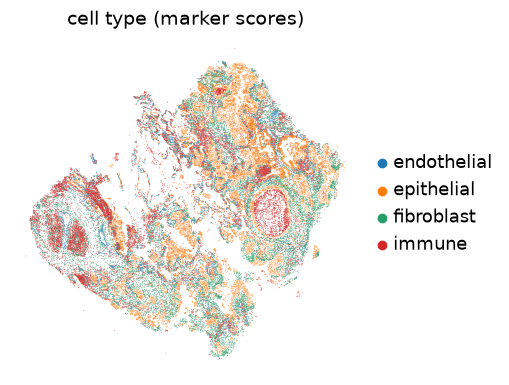

In [5]:
cnv.pl.spatial_cnv(adata, color="cell_type", size=1, title="cell type (marker scores)")

## Gene positions

The genomic positions of the genes come from the GENCODE v44 annotation, downloaded once with {mod}`pooch`. The
Xenium panel lists Ensembl gene ids, which we match to the GTF.

In [6]:
gtf = pooch.retrieve(
    "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_44/gencode.v44.annotation.gtf.gz",
    known_hash="sha256:01f817afed65feee863361b4baf30a95e722ee5c5d508ff77b04106ef7ba20d3",
    fname="gencode.v44.annotation.gtf.gz",
    path=pooch.os_cache("infercnvpy"),
)
cnv.io.genomic_position_from_gtf(gtf, adata, gtf_gene_id="gene_id", adata_gene_id="gene_ids")
genes_per_chromosome = adata.var["chromosome"].value_counts()
genes_per_chromosome[genes_per_chromosome.index.str.fullmatch(r"chr[0-9]+")].agg(["min", "max"])

min     58
max    536
Name: count, dtype: int64

## Infer CNVs and smooth them over the tissue

{func}`infercnvpy.tl.infercnv` runs as for single-cell data. The panel has 58 to 536 genes per autosome (printed above),
so we use running windows of 51 genes, every 5 genes, instead of the defaults
(100 and 10). We turn off the noise filter (`dynamic_threshold=None`), because it sets small values to 0 and
{func}`infercnvpy.tl.smooth_cnv` would then average those zeros. Then we build a spatial graph of the 10 nearest
neighbours of each cell with squidpy and average each cell's CNV profile with its neighbours. By default, the cell
itself counts as one more neighbour.

In [7]:
cnv.tl.infercnv(
    adata,
    reference_key="cell_type",
    reference_cat=["immune", "endothelial", "fibroblast"],
    window_size=51,
    step=5,
    dynamic_threshold=None,
)
sq.gr.spatial_neighbors_knn(adata, n_neighs=10)
cnv.tl.smooth_cnv(adata)
adata.obsm["X_cnv"].shape, adata.obsm["X_cnv_smoothed"].shape

INFO     Creating graph using `None` transform and `1` libraries.                                                  


((56265, 744), (56265, 744))

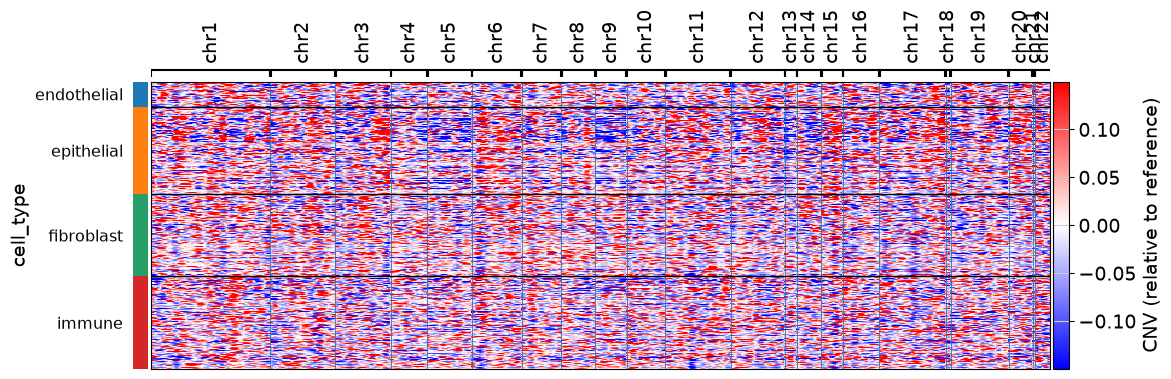

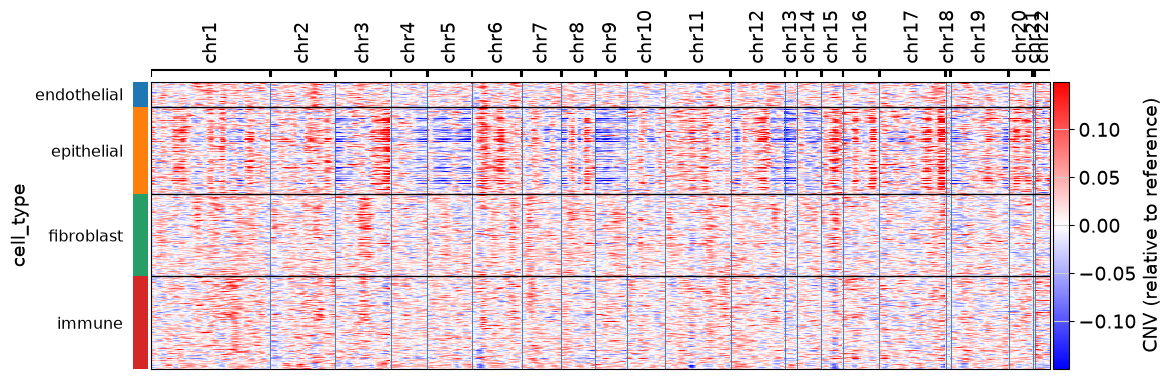

In [8]:
heatmap = {"groupby": "cell_type", "figsize": (12, 4), "vmin": -0.15, "vmax": 0.15}
cnv.pl.chromosome_heatmap(adata, **heatmap)
cnv.pl.chromosome_heatmap(adata, use_rep="cnv_smoothed", **heatmap)

Smoothing removes much of the noise of single cells, and the epithelial cells show a loss of 3p and a gain of 3q.
On the tissue, we plot the mean CNV of each arm of chromosome 3 (the windows whose midpoint lies in the arm, using the
window positions that `tl.infercnv` stores; the centromere is at about 91 Mb in GRCh38). The loss of 3p marks epithelial
regions of the section. The 3q map is red across most of the section, including regions of fibroblasts and immune
cells, so 3q is less specific here.

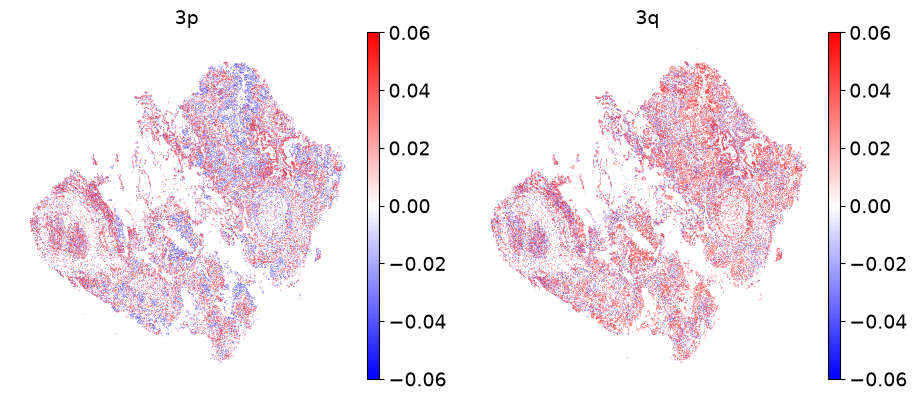

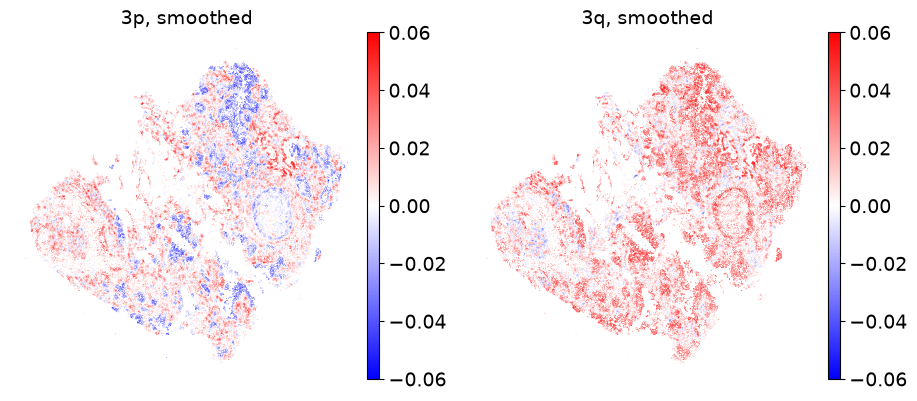

In [9]:
arms = ["chr3:0-90_000_000", "chr3:93_000_000-199_000_000"]
cnv.pl.spatial_cnv(adata, region=arms, size=1, vmin=-0.06, vmax=0.06, title=["3p", "3q"])
cnv.pl.spatial_cnv(
    adata, region=arms, use_rep="cnv_smoothed", size=1, vmin=-0.06, vmax=0.06, title=["3p, smoothed", "3q, smoothed"]
)

## Tumour calls

We score each cell by the mean absolute value of its smoothed CNV profile and call it tumour when the score is above
the 95th percentile of the scores of the reference cells, so the score and the threshold are both per cell. By
construction, 5% of the reference cells are called tumour, and normal cells of types outside the reference can exceed
the threshold as well.

In [10]:
reference = adata.obs["cell_type"].isin(["immune", "endothelial", "fibroblast"]).to_numpy()
cell_score = np.abs(adata.obsm["X_cnv_smoothed"]).mean(axis=1)
threshold = np.quantile(cell_score[reference], 0.95)
adata.obs["cnv_call"] = pd.Categorical(np.where(cell_score > threshold, "tumour", "normal"))
calls = pd.crosstab(adata.obs["cell_type"], adata.obs["cnv_call"])
print(f"threshold: {threshold:.4f}")
print(
    f"share of tumour calls that are not epithelial: {1 - calls.loc['epithelial', 'tumour'] / calls['tumour'].sum():.1%}"
)
calls

threshold: 0.0363
share of tumour calls that are not epithelial: 16.0%


cnv_call,normal,tumour
cell_type,,
endothelial,4779,145
epithelial,6848,10271
fibroblast,15393,718
immune,17016,1095


Most epithelial cells are called tumour. The fibroblasts, immune and endothelial cells among the tumour calls (share
printed above) are the 5% of reference cells above the threshold. The tumour calls show the loss of 3p, the gain of
3q and losses on chromosomes 4, 5 and 9.

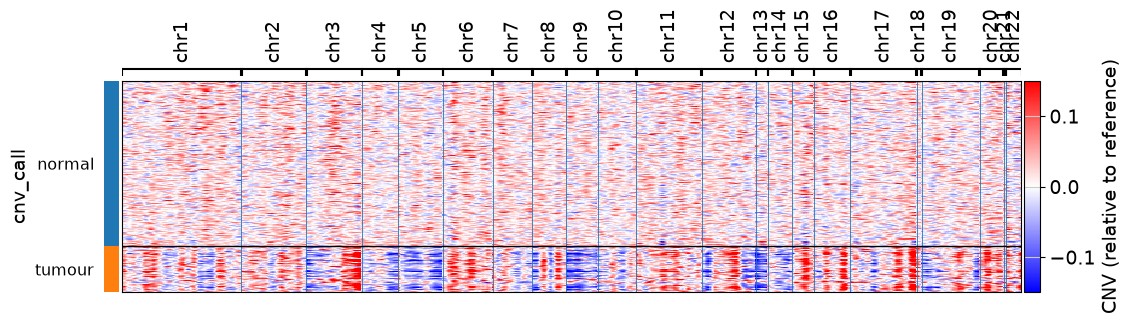

In [11]:
cnv.pl.chromosome_heatmap(adata, groupby="cnv_call", use_rep="cnv_smoothed", figsize=(12, 3), vmin=-0.15, vmax=0.15)

## Spatially coherent regions

{func}`infercnvpy.tl.spatial_regions` makes labels spatially coherent: a cell takes the label of its neighbourhood
when enough neighbours disagree with it (for two labels and the default `beta=2`, more than 75% of them).
The calls from the smoothed profiles are already spatially coherent, and few cells change.

In [12]:
cnv.tl.spatial_regions(adata, key="cnv_call")
print(f"{(adata.obs['cnv_call'] != adata.obs['cnv_call_spatial']).sum()} of {adata.n_obs} cells changed their label")
pd.crosstab(adata.obs["cnv_call"], adata.obs["cnv_call_spatial"])

600 of 56265 cells changed their label


cnv_call_spatial,normal,tumour
cnv_call,,
normal,43866,170
tumour,430,11799


The prior matters more for noisy labels. Calls of single cells from the unsmoothed CNV profiles, with the same rule,
are scattered over the section (left in the figure below). With `beta=4` (a cell changes its label when more than
62.5% of its neighbours disagree), `tl.spatial_regions` removes about half of the tumour calls (8,788 to 4,710 in the
table below), including 89% of the calls of non-epithelial cells (middle). It doesn't recover tumour cells that the
unsmoothed profiles miss, so the regularised calls from the smoothed profiles (right) include more than twice as many
epithelial cells.

In [13]:
raw_score = np.asarray(abs(adata.obsm["X_cnv"]).mean(axis=1)).ravel()
raw_threshold = np.quantile(raw_score[reference], 0.95)
adata.obs["cnv_call_raw"] = pd.Categorical(np.where(raw_score > raw_threshold, "tumour", "normal"))
cnv.tl.spatial_regions(adata, key="cnv_call_raw", beta=4)
epithelial = np.where(adata.obs["cell_type"] == "epithelial", "epithelial", "other")
keys = ["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"]
pd.DataFrame({key: (adata.obs[key] == "tumour").groupby(epithelial).sum() for key in keys}).T.rename_axis(
    "tumour calls"
)

,epithelial,other
tumour calls,,
cnv_call_raw,6830,1958
cnv_call_raw_spatial,4502,208
cnv_call_spatial,10250,1719


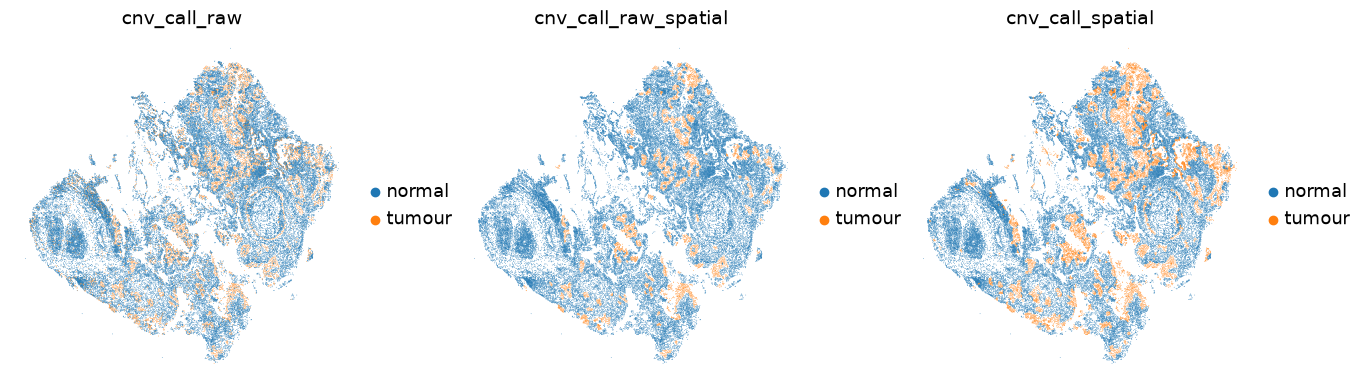

In [14]:
cnv.pl.spatial_cnv(adata, color=["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"], size=1)

## Notes

- With 10 neighbours and the default weight of the cell itself, a cell's own profile is 1/11 of its smoothed profile, so calls from
  smoothed profiles are calls of neighbourhoods. Smoothing mixes the profiles of tumour and normal cells at the
  tumour boundary and of immune cells that infiltrate the tumour, over about `n_hops` cells. Use the unsmoothed
  `X_cnv` for per-cell questions in mixed regions.
- The spatial graph defines the neighbourhood. A kNN graph adapts to the cell density; a radius graph
  ({func}`squidpy.gr.spatial_neighbors_radius`) keeps the physical scale fixed. `n_hops=2` in `tl.smooth_cnv`
  widens the neighbourhood further.
- `tl.spatial_regions` changes labels only as long as a single change makes them more coherent, so the result stays
  close to the input labels and is not a new clustering. Larger `beta` gives smoother regions.